<a href="https://colab.research.google.com/github/Deangr-econ/torch-volatility-engine/blob/main/HAR_Markov_Switching.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import torch
import time
import numba
from scipy.optimize import minimize
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
# from statsmodels.tsa.regime_switching.markov_regression import MarkovRegression

# 1. Load data
data_futures = pd.read_csv(
    "https://github.com/Deangr-econ/torch-volatility-engine/raw/main/realized_variance_futures.csv")
# 2. Filter symbol & set date index directly
df = (
    data_futures.query("symbol == 'NG'")
    .set_index('date')[['rv5', 'rsp5', 'rsn5']]
)

# 3. Feature engineering (HAR daily, weekly, monthly features)
data = df[['rsp5', 'rsn5', 'rv5']].copy()

for feature in ['rsp5', 'rsn5', 'rv5']:
    data[f'{feature}_w'] = data[feature].rolling(5).mean()   # Added ()
    data[f'{feature}_m'] = data[feature].rolling(22).mean()  # Added ()

# Lag all features by 1 day to prevent look-ahead bias
data = data.shift(1)

# Add target column back and drop initial rolling NaNs
data['rv5_p'] = df['rv5']
data = data.dropna()

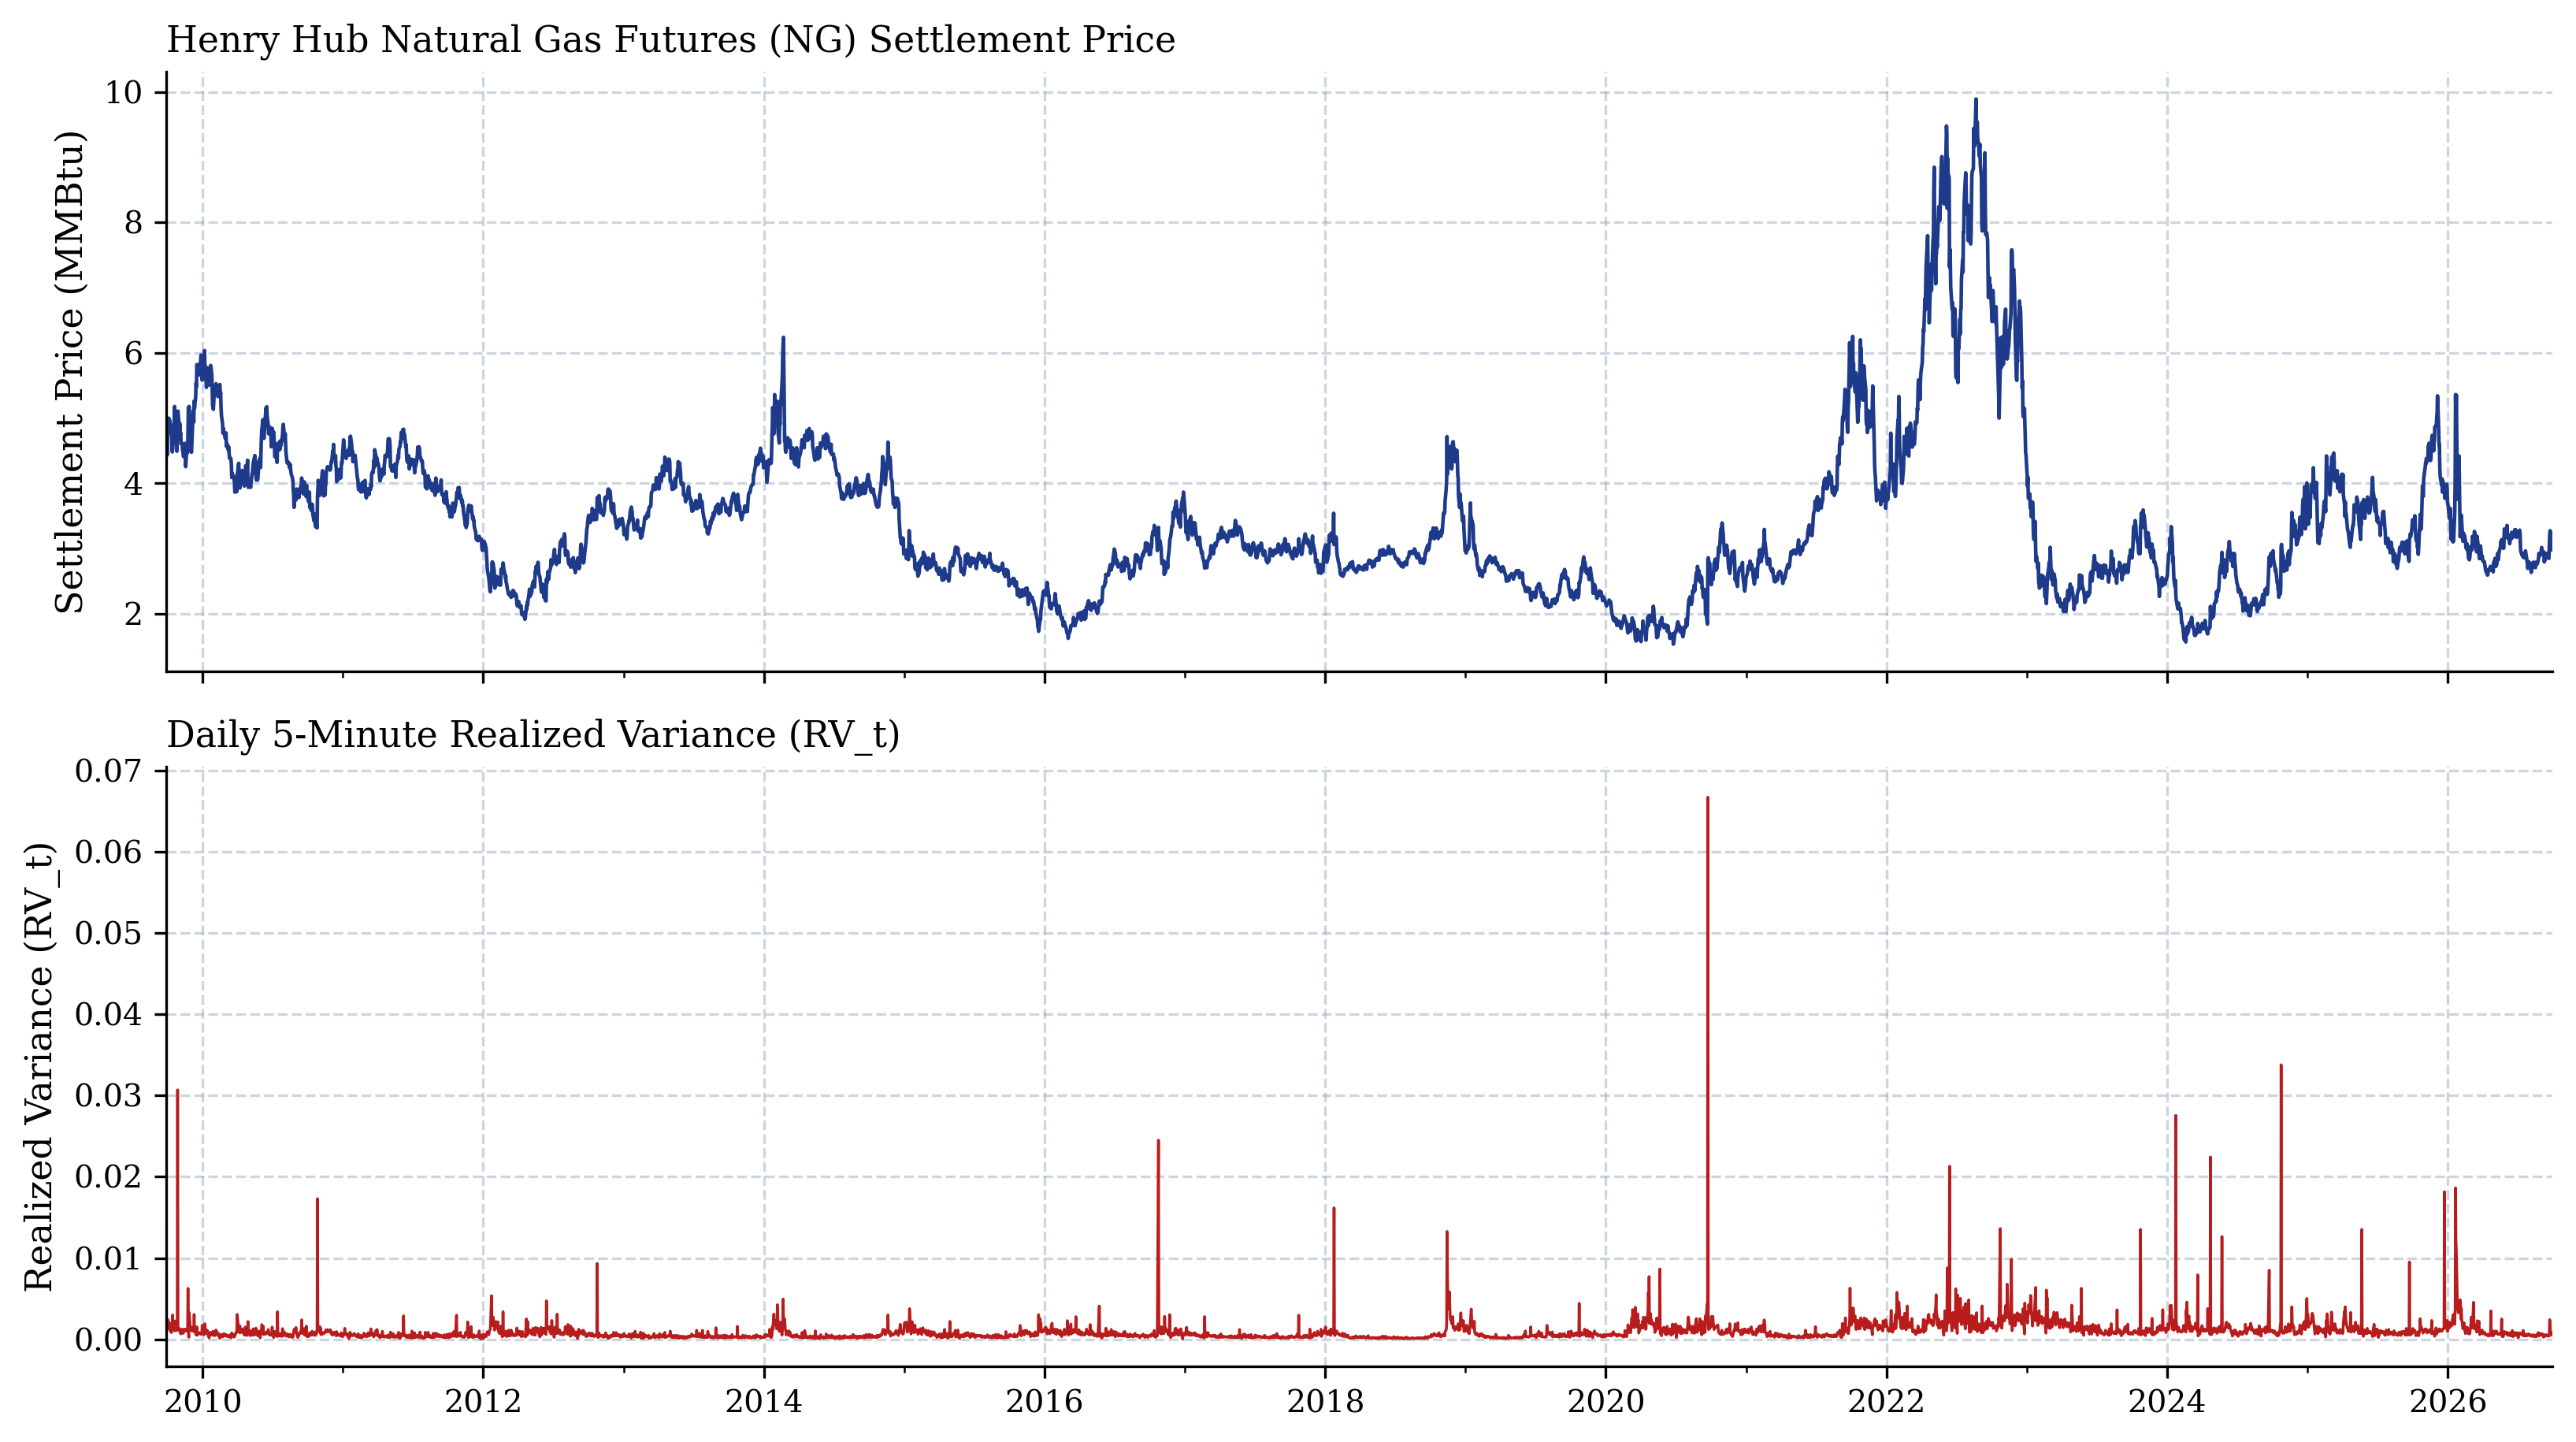

In [2]:
df2 = (
    data_futures.query("symbol == 'NG'")
    .set_index('date')[['rv5', 'rsp5', 'rsn5', 'close_price']]
).copy()


# 1. Ensure the DatetimeIndex is parsed correctly (prevents categorical tick clutter)
plot_df = df2.copy()
plot_df.index = pd.to_datetime(plot_df.index)

# 2. Set academic publication styling (clean serif / high-contrast palette)
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 10,
    'axes.labelsize': 11,
    'axes.titlesize': 11,
    'xtick.labelsize': 9.5,
    'ytick.labelsize': 9.5,
    'lines.linewidth': 1.0,
    'mathtext.fontset': 'cm',  # Computer Modern math formatting for LaTeX look
})

fig, axes = plt.subplots(2, 1, figsize=(11, 6.2), sharex=True, dpi=300)

# -------------------------------------------------------------------------
# Panel A: Natural Gas Futures Close / Settlement Price
# -------------------------------------------------------------------------
color_price = '#1e3a8a'  # Deep Navy
axes[0].plot(plot_df.index, plot_df['close_price'], color=color_price, lw=1.1)
axes[0].set_ylabel('Settlement Price (MMBtu)', fontweight='medium')
axes[0].set_title(r'Henry Hub Natural Gas Futures (NG) Settlement Price',
                  loc='left', fontsize=11, pad=6)
axes[0].grid(True, linestyle='--', alpha=0.45, color='#94a3b8')
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

# -------------------------------------------------------------------------
# Panel B: 5-Minute Realized Variance (rv5)
# -------------------------------------------------------------------------
color_rv = '#b91c1c'  # Crimson / Brick Red
axes[1].plot(plot_df.index, plot_df['rv5'], color=color_rv, lw=0.85)
axes[1].set_ylabel(r'Realized Variance (RV_t)', fontweight='medium')
axes[1].set_title(r'Daily 5-Minute Realized Variance (RV_t)',
                  loc='left', fontsize=11, pad=6)
axes[1].grid(True, linestyle='--', alpha=0.45, color='#94a3b8')
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

# -------------------------------------------------------------------------
# Formatting Time Axis
# -------------------------------------------------------------------------
# Set major ticks every 2 years and minor ticks every 1 year
axes[1].xaxis.set_major_locator(mdates.YearLocator(2))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
axes[1].xaxis.set_minor_locator(mdates.YearLocator(1))
axes[1].set_xlim(plot_df.index.min(), plot_df.index.max())

plt.tight_layout()

# Save in vector format for LaTeX / Overleaf (.pdf) and 300 DPI raster (.png)
plt.savefig('figure_ng_price_rv5.pdf', bbox_inches='tight')
plt.savefig('figure_ng_price_rv5.png', dpi=300, bbox_inches='tight')
plt.show()

In [3]:
def build_tensor(df, target_col='rv5', train_pct=0.80):
    """
    Packs expanding window feature matrices and target vectors into 3D tensors.

    Returns:
        X_3d: Tensor of shape (test_size, max_window_len, K)
        y_3d: Tensor of shape (test_size, max_window_len)
        X_test: Out-of-sample feature vectors of shape (test_size, 1, K)
        y_test: Actual out-of-sample target values of shape (test_size,)
    """
    # 1. Separate features and target
    feature_cols = [col for col in df.columns if col != target_col]

    # Extract values and create constant term for X
    y_tensor = torch.tensor(df[target_col].values, dtype=torch.float64)

    X_df = df[feature_cols].assign(const=1.0)[['const'] + feature_cols]
    X_tensor = torch.tensor(X_df.values, dtype=torch.float64)

    # 2. Calculate dimensions
    N, K = X_tensor.shape
    train_split = int(train_pct * N)
    test_size = N - train_split
    max_window_len = N - 1  # Maximum row length across all expanding windows

    # 3. Initialize 3D containers (padded with zeros)
    X_3d = torch.zeros((test_size, max_window_len, K), dtype=torch.float64)
    y_3d = torch.zeros((test_size, max_window_len), dtype=torch.float64)

    # 4. Fill expanding window slices (LEGO blocks)
    for i in range(test_size):
        cur_len = train_split + i
        X_3d[i, :cur_len, :] = X_tensor[:cur_len, :]
        y_3d[i, :cur_len] = y_tensor[:cur_len]

    X_test = X_tensor[train_split:N, :].unsqueeze(1)
    y_test = y_tensor[train_split:N]

    return X_3d, y_3d, X_test, y_test


def solve_expanding_ols(X_3d, y_3d, X_test):
    """
    Solves M expanding-window OLS regressions simultaneously and generates
    1-step-ahead out-of-sample forecasts using PyTorch batched tensor ops.

    Parameters:
    -----------
    X_3d   : Tensor of shape (M, max_window_len, K)
    y_3d   : Tensor of shape (M, max_window_len)
    X_test : Tensor of shape (M, 1, K)

    Returns:
    --------
    y_pred : Tensor of shape (M,) containing 1-step-ahead forecasts
    betas  : Tensor of shape (M, K) containing estimated coefficients for all windows
    """
    # 1. Reshape y_3d to (M, max_window_len, 1) for matrix multiplication
    y_3d_col = y_3d.unsqueeze(-1)

    # 2. Compute X^T * X for all M windows simultaneously -> Shape: (M, K, K)
    # transpose(1, 2) flips (max_window_len, K) to (K, max_window_len)
    XtX = torch.bmm(X_3d.transpose(1, 2), X_3d)

    # 3. Compute X^T * y for all M windows simultaneously -> Shape: (M, K, 1)
    Xty = torch.bmm(X_3d.transpose(1, 2), y_3d_col)

    # 4. Solve XtX * beta = Xty for beta across all M models -> Shape: (M, K, 1)
    betas_col = torch.linalg.solve(XtX, Xty)

    # 5. Generate 1-step-ahead predictions: X_test * beta -> Shape: (M, 1, 1)
    y_pred_3d = torch.bmm(X_test, betas_col)

    # 6. Flatten dimensions back to clean 1D and 2D arrays
    y_pred = y_pred_3d.squeeze()       # Shape: (M,)
    betas = betas_col.squeeze(-1)       # Shape: (M, K)

    return y_pred, betas

def rmsfe(y_true, y_pred):
  return torch.sqrt(torch.mean((y_true - y_pred) ** 2)).item()

def FSP(df, target_col='rv5', train_pct=0.80):
    X_3d, y_3d, X_test, y_test = build_tensor(df, target_col, train_pct)
    y_pred, betas = solve_expanding_ols(X_3d, y_3d, X_test)
    rmsfe_val = rmsfe(y_test, y_pred)

    return rmsfe_val, y_pred, betas, y_test

def get_forecast_metrics(y_true, y_pred, is_log=False):
    """
    Computes core out-of-sample volatility forecasting performance metrics.

    Parameters:
    -----------
    y_true : array-like
        Actual volatility series.
    y_pred : array-like
        Forecasted volatility series.
    is_log : bool, optional
        If True, exponentiates both arrays before calculating metrics to evaluate on original scale.

    Returns:
    --------
    dict
        A dictionary containing RMSE, MAE, and QLIKE values.
    """
    # Convert to numpy arrays if necessary
    y_t = np.array(y_true)
    y_p = np.array(y_pred)

    if is_log:
        y_t = np.exp(y_t)
        y_p = np.exp(y_p)

    rmse = np.sqrt(np.mean((y_t - y_p) ** 2))
    mae = np.mean(np.abs(y_t - y_p))

    # QLIKE loss: standard asymmetric loss function for volatility forecasts
    # Handles dividing by zero with safety checks
    with np.errstate(divide='ignore', invalid='ignore'):
        qlike = np.mean(y_t / y_p - np.log(y_t / y_p) - 1.0) if np.all(y_p > 0) else np.nan

    return {
        'RMSE': float(rmse),
        'MAE': float(mae),
        'QLIKE': float(qlike)
    }

# Example of usage:
# metrics = get_forecast_metrics(y_test_base_np, pred_base_ols_np)
# print(metrics)

In [4]:
# =============================================================================
# 1. GENERAL M-REGIME COMPILED HAMILTON LOG-LIKELIHOOD KERNEL
# =============================================================================
@numba.njit(fastmath=True)
def fast_hamilton_ll_general(mu_mat, y, sigmas, P):
    """
    General M-regime Hamilton Filter Kernel.

    mu_mat : (T, M) - conditional means per regime
    y      : (T,)   - observed target series
    sigmas : (M,)   - error standard deviations per regime
    P      : (M, M) - transition matrix where P[i, j] = Prob(S_t = j | S_{t-1} = i)
    """
    T, M = mu_mat.shape
    inv_sigmas = 1.0 / (sigmas * 2.506628274631)

    # -------------------------------------------------------------
    # Stationary / Ergodic Steady-State Prior: (P.T - I) * pi = 0
    # -------------------------------------------------------------
    A = np.copy(P.T)
    for m in range(M):
        A[m, m] -= 1.0
    for m in range(M):
        A[M - 1, m] = 1.0  # Replace last equation with sum(pi) = 1

    b = np.zeros(M)
    b[M - 1] = 1.0

    # Solve linear system; fallback to uniform prior if singular
    try:
        xi = np.linalg.solve(A, b)
        for m in range(M):
            if xi[m] < 0.0 or np.isnan(xi[m]):
                xi = np.ones(M) / M
                break
    except:
        xi = np.ones(M) / M

    ll = 0.0
    pr = np.zeros(M)
    eta = np.zeros(M)

    # -------------------------------------------------------------
    # Main Filter Time Loop
    # -------------------------------------------------------------
    for t in range(T):
        # 1. State projection: pr = P.T @ xi
        for j in range(M):
            acc = 0.0
            for i in range(M):
                acc += P[i, j] * xi[i]
            pr[j] = acc

        # 2. Gaussian conditional densities
        yt = y[t]
        for m in range(M):
            e = (yt - mu_mat[t, m]) / sigmas[m]
            eta[m] = inv_sigmas[m] * np.exp(-0.5 * e * e)

        # 3. Mixture density
        f = 0.0
        for m in range(M):
            f += pr[m] * eta[m]

        if f < 1e-300:
            f = 1e-300
        ll += np.log(f)

        # 4. Bayesian Posterior Update
        inv_f = 1.0 / f
        for m in range(M):
            xi[m] = (pr[m] * eta[m]) * inv_f

    return ll, xi


# =============================================================================
# 2. MATRIX TRANSFORMATIONS & UNCONSTRAINED REPARAMETERIZATION
# =============================================================================
def logits_to_P(logits_matrix):
    """
    Numerically stable row-wise Softmax: converts unconstrained (M, M) logits
    into a valid row-stochastic transition matrix P where each row sums to 1.
    """
    shift = logits_matrix - np.max(logits_matrix, axis=1, keepdims=True)
    exp_logits = np.exp(shift)
    return exp_logits / np.sum(exp_logits, axis=1, keepdims=True)


def P_to_logits(P):
    """
    Converts a valid transition matrix P to logit space.
    """
    return np.log(np.clip(P, 1e-6, 1.0 - 1e-6))


# =============================================================================
# 3. GENERAL OBJECTIVE WRAPPER
# =============================================================================
def objective_hamilton_general(theta, X, y, K, M):
    """
    Layout of theta:
      - theta[0 : M*K]               -> Betas (K x M)
      - theta[M*K : M*K + M]         -> Sigmas (M,)
      - theta[M*K + M : M*K + M + M^2] -> Transition matrix logits (M x M)
    """
    n_betas = M * K
    betas = theta[:n_betas].reshape(K, M)
    sigmas = theta[n_betas : n_betas + M]
    logits = theta[n_betas + M : n_betas + M + (M * M)].reshape(M, M)

    # Boundary penalty
    if np.any(sigmas <= 1e-5):
        return 1e12

    P = logits_to_P(logits)

    # Pre-calculate all M regime paths simultaneously: (T, M)
    mu_mat = X @ betas

    ll, _ = fast_hamilton_ll_general(mu_mat, y, sigmas, P)

    if np.isnan(ll) or np.isinf(ll):
        return 1e12

    return -ll


# =============================================================================
# 4. INITIALIZATION & SINGLE-WINDOW ESTIMATION
# =============================================================================
def get_initial_theta_general(X_init, y_init, K, M):
    """
    Derives warm-start parameters for arbitrary M regimes from baseline OLS.
    """
    beta_ols = np.linalg.lstsq(X_init, y_init, rcond=None)[0]
    resids = y_init - X_init @ beta_ols
    s_ols = float(np.std(resids))

    # Multipliers spanning lower to higher volatility regimes
    sigma_scales = np.linspace(0.70, 1.60, M)
    beta_scales = np.linspace(0.95, 1.05, M)

    betas_init = np.outer(beta_ols, beta_scales)  # Shape (K, M)
    sigmas_init = s_ols * sigma_scales            # Shape (M,)

    # Sticky diagonal transition matrix prior (e.g., 0.90 on diagonal)
    P_init = np.full((M, M), (1.0 - 0.90) / (M - 1))
    np.fill_diagonal(P_init, 0.90)
    logits_init = P_to_logits(P_init)

    return np.concatenate([
        betas_init.ravel(),
        sigmas_init,
        logits_init.ravel()
    ])


def fit_window_general(theta_start, X_train, y_train, K, M, bounds, maxiter=50):
    """
    Fits one window using SciPy L-BFGS-B with arbitrary M regimes.
    """
    opt_res = minimize(
        fun=objective_hamilton_general,
        x0=theta_start,
        args=(X_train, y_train, K, M),
        method='L-BFGS-B',
        bounds=bounds,
        options={'maxiter': maxiter, 'ftol': 1e-6, 'gtol': 1e-4}
    )
    if opt_res.success or opt_res.fun < 1e10:
        return opt_res.x, opt_res.fun
    return theta_start, opt_res.fun


# =============================================================================
# 5. 1-STEP FORECASTING PROJECTION
# =============================================================================
def predict_one_step_general(theta, X_train, y_train, x_next, K, M):
    """
    Extracts terminal filtered state, projects forward via P.T, and computes
    1-step ahead expected conditional variance.
    """
    n_betas = M * K
    betas = theta[:n_betas].reshape(K, M)
    sigmas = theta[n_betas : n_betas + M]
    logits = theta[n_betas + M : n_betas + M + (M * M)].reshape(M, M)
    P = logits_to_P(logits)

    # 1. In-sample fit & terminal filtered state extraction
    mu_mat = X_train @ betas
    _, xi_T = fast_hamilton_ll_general(mu_mat, y_train, sigmas, P)

    # 2. Project state forward 1 step: xi_{t+1|t} = P.T @ xi_T
    xi_next = P.T @ xi_T

    # 3. Compute conditional expectations for tomorrow: (M,)
    mu_next = x_next @ betas

    # 4. Final mixture expectation
    y_hat = np.dot(xi_next, mu_next)

    return y_hat, xi_next


def evaluate_forecasts(y_true, y_pred, is_log=False):
    """
    Computes standard volatility loss metrics: RMSE, MAE, and QLIKE.
    """
    y_t = np.exp(y_true) if is_log else y_true
    y_p = np.exp(y_pred) if is_log else y_pred

    rmse = np.sqrt(np.mean((y_t - y_p) ** 2))
    mae = np.mean(np.abs(y_t - y_p))
    qlike = np.mean(y_t / y_p - np.log(y_t / y_p) - 1.0) if np.all(y_p > 0) else np.nan

    return {'RMSE': rmse, 'MAE': mae, 'QLIKE': qlike}


# =============================================================================
# 6. MASTER ENGINE: run_ms_har_forecasting
# =============================================================================
def run_ms_har_forecasting(
    data,
    target_col,
    exog_cols=None,
    train_split=0.80,
    n_regimes=2,
    is_log=True,
    verbose=True
):
    """
    Executes an expanding window out-of-sample forecasting pipeline using an MS-HAR model
    generalized to an arbitrary number of regimes M.

    Parameters:
    -----------
    data : pd.DataFrame
        Full dataset containing features and target.
    target_col : str
        Name of the dependent variable column.
    exog_cols : list of str, optional
        List of exogenous feature column names. If None, uses all columns except target_col.
    train_split : float, optional
        Fraction of data used for initial in-sample calibration (default: 0.80).
    n_regimes : int, optional
        Number of regimes M (e.g., 2, 3, 4).
    is_log : bool, optional
        Whether the target variable is modeled in logarithms.
    verbose : bool, optional
        Whether to print rolling execution progress.

    Returns:
    --------
    dict containing:
        - 'forecasts': np.ndarray of out-of-sample predictions
        - 'regime_probs': np.ndarray of shape (N_oos, M) with predicted regime probabilities
        - 'param_history': np.ndarray of shape (N_oos, n_params) with estimated parameters
        - 'metrics': dict with RMSE, MAE, QLIKE
        - 'y_true': np.ndarray of actual out-of-sample targets
        - 'total_time': total execution time in seconds
    """
    M = int(n_regimes)
    if M < 2:
        raise ValueError("n_regimes must be >= 2.")

    # 1. Feature matrix & Target vector preparation
    if exog_cols is None:
        exog_cols = [c for c in data.columns if c != target_col]

    X_full = np.ascontiguousarray(data[exog_cols].values, dtype=np.float64)
    y_full = np.ascontiguousarray(data[target_col].values, dtype=np.float64)

    N_total, K = X_full.shape
    T_start = int(N_total * train_split)
    n_forecasts = N_total - T_start
    n_params = (M * K) + M + (M * M)

    if verbose:
        print(f"Model Configuration: {M} Regimes | {K} Exogenous Variables | {n_params} Parameters")
        print(f"Total Observations: {N_total} | Initial Calibration: {T_start} | Forecast Horizon: {n_forecasts}")

    # 2. Box bounds for L-BFGS-B
    # Betas: unconstrained
    # Sigmas: strictly positive [1e-4, 50.0]
    # Logits: unconstrained [-15.0, 15.0] (prevents numerical overflow in Softmax)
    bounds = (
        [(None, None)] * (M * K) +
        [(1e-4, 50.0)] * M +
        [(-15.0, 15.0)] * (M * M)
    )

    # 3. Initial Window Calibration (Cold Start)
    if verbose:
        print("Calibrating initial window (Cold Start)...")
    theta_init = get_initial_theta_general(X_full[:T_start], y_full[:T_start], K, M)
    current_theta, init_ll = fit_window_general(
        theta_init, X_full[:T_start], y_full[:T_start], K, M, bounds, maxiter=150
    )

    # 4. Pre-allocate Output Arrays
    y_hat_oos = np.zeros(n_forecasts, dtype=np.float64)
    regime_prob_oos = np.zeros((n_forecasts, M), dtype=np.float64)
    param_history = np.zeros((n_forecasts, n_params), dtype=np.float64)

    # 5. Expanding Window Rolling Loop
    start_time = time.time()
    for i in range(n_forecasts):
        t_end = T_start + i

        X_train = X_full[:t_end]
        y_train = y_full[:t_end]
        x_next = X_full[t_end]

        # Warm-started optimization
        current_theta, fun_val = fit_window_general(
            current_theta, X_train, y_train, K, M, bounds, maxiter=50
        )
        param_history[i] = current_theta

        # 1-step forecast & state projection
        y_hat, probs = predict_one_step_general(current_theta, X_train, y_train, x_next, K, M)
        y_hat_oos[i] = y_hat
        regime_prob_oos[i] = probs

        if verbose and ((i + 1) % 100 == 0 or i == 0 or i == n_forecasts - 1):
            elapsed = time.time() - start_time
            speed = (i + 1) / elapsed
            print(f"Step {i+1:3d}/{n_forecasts} | Elapsed: {elapsed:5.1f}s | Speed: {speed:4.1f} win/s | -LL: {fun_val:7.2f}")

    total_time = time.time() - start_time
    y_true_oos = y_full[T_start:]

    # 6. Evaluation
    metrics = evaluate_forecasts(y_true_oos, y_hat_oos, is_log=is_log)

    if verbose:
        print(f"\nExecution Complete in {total_time:.2f}s ({total_time / n_forecasts * 1000:.1f} ms/window).")
        print(f"RMSE:  {metrics['RMSE']:.6f} | MAE: {metrics['MAE']:.6f} | QLIKE: {metrics['QLIKE']:.6f}")

    return {
            'forecasts': y_hat_oos,
            'regime_probs': regime_prob_oos,
            'param_history': param_history,
            'metrics': metrics,
            'y_true': y_true_oos,
            'total_time': total_time
        }

In [5]:
data_model = data.copy()

# Configure which regimes you want to dynamically test/compare
regimes_to_test = [*range(2,8)]

# Define the three different predictor groups
predictor_groups = {
    'rv5 Only': ['rv5'],
    'rv5 HAR': ['rv5', 'rv5_w', 'rv5_m'],
    'RS HAR': ['rsp5', 'rsn5', 'rsp5_w', 'rsn5_w', 'rsp5_m', 'rsn5_m']
}

results_dict_rv = {}

for group_name, exog_cols in predictor_groups.items():
    # -----------------------------------------------------
    # 1. Base OLS Estimation (No regimes)
    # -----------------------------------------------------
    print(f"Estimating OLS Model for {group_name}...")
    df_subset = data_model[['rv5_p'] + exog_cols].copy()
    _, pred_tensor, _, y_test_tensor = FSP(df_subset, target_col='rv5_p', train_pct=0.80)

    metrics_ols = get_forecast_metrics(y_test_tensor.numpy(), pred_tensor.numpy(), is_log=False)
    results_dict_rv[f'OLS: {group_name}'] = metrics_ols

    # -----------------------------------------------------
    # 2. Dynamic Regime Switching Models
    # -----------------------------------------------------
    for r in regimes_to_test:
        print(f"Estimating {r}-Regime Model for {group_name}...")
        res_rs = run_ms_har_forecasting(
            data=data_model,
            target_col='rv5_p',
            exog_cols=exog_cols,
            train_split=0.80,
            n_regimes=r,
            is_log=False,
            verbose=False
        )
        results_dict_rv[f'RS ({r} Regimes): {group_name}'] = res_rs['metrics']

# =====================================================
# Build Comparison Matrix
# =====================================================
comparison_matrix_rv = pd.DataFrame(results_dict_rv).T
print("\n=================== COMPARISON MATRIX (LEVEL RV) ===================")
display(comparison_matrix_rv.style.highlight_min(axis=0, color='lightgreen'))

Estimating OLS Model for rv5 Only...
Estimating 2-Regime Model for rv5 Only...
Estimating 3-Regime Model for rv5 Only...
Estimating 4-Regime Model for rv5 Only...
Estimating 5-Regime Model for rv5 Only...
Estimating 6-Regime Model for rv5 Only...
Estimating 7-Regime Model for rv5 Only...
Estimating OLS Model for rv5 HAR...
Estimating 2-Regime Model for rv5 HAR...
Estimating 3-Regime Model for rv5 HAR...
Estimating 4-Regime Model for rv5 HAR...
Estimating 5-Regime Model for rv5 HAR...
Estimating 6-Regime Model for rv5 HAR...
Estimating 7-Regime Model for rv5 HAR...
Estimating OLS Model for RS HAR...
Estimating 2-Regime Model for RS HAR...
Estimating 3-Regime Model for RS HAR...
Estimating 4-Regime Model for RS HAR...
Estimating 5-Regime Model for RS HAR...
Estimating 6-Regime Model for RS HAR...
Estimating 7-Regime Model for RS HAR...

=================== COMPARISON MATRIX (LEVEL RV) ===================


,RMSE,MAE,QLIKE
OLS: rv5 Only,0.002154,0.000648,0.277352
RS (2 Regimes): rv5 Only,0.002204,0.000680,0.380902
RS (3 Regimes): rv5 Only,0.002157,0.000649,0.332405
RS (4 Regimes): rv5 Only,0.002137,0.000639,0.319256
RS (5 Regimes): rv5 Only,0.002128,0.000636,0.315449
RS (6 Regimes): rv5 Only,0.002217,0.000663,0.310376
RS (7 Regimes): rv5 Only,0.002171,0.000654,0.314344
OLS: rv5 HAR,0.002107,0.000670,0.235017
RS (2 Regimes): rv5 HAR,0.002110,0.000648,0.235491
RS (3 Regimes): rv5 HAR,0.002101,0.000630,0.234457


In [6]:
data_model = np.log(data).copy()

# Configure which regimes you want to dynamically test/compare
regimes_to_test = [*range(2,8)]

# Define the three different predictor groups
predictor_groups = {
    'rv5 Only': ['rv5'],
    'rv5 HAR': ['rv5', 'rv5_w', 'rv5_m'],
    'RS HAR': ['rsp5', 'rsn5', 'rsp5_w', 'rsn5_w', 'rsp5_m', 'rsn5_m']
}

results_dict_log_rv = {}

for group_name, exog_cols in predictor_groups.items():
    # -----------------------------------------------------
    # 1. Base OLS Estimation (No regimes)
    # -----------------------------------------------------
    print(f"Estimating OLS Model for {group_name}...")
    df_subset = data_model[['rv5_p'] + exog_cols].copy()
    _, pred_tensor, _, y_test_tensor = FSP(df_subset, target_col='rv5_p', train_pct=0.80)

    # FIXED: Since df_subset is logged, we must pass is_log=True to get level-scale metrics!
    metrics_ols = get_forecast_metrics(y_test_tensor.numpy(), pred_tensor.numpy(), is_log=True)
    results_dict_log_rv[f'OLS: {group_name}'] = metrics_ols

    # -----------------------------------------------------
    # 2. Dynamic Regime Switching Models
    # -----------------------------------------------------
    for r in regimes_to_test:
        print(f"Estimating {r}-Regime Model for {group_name}...")
        res_rs = run_ms_har_forecasting(
            data=data_model,
            target_col='rv5_p',
            exog_cols=exog_cols,
            train_split=0.80,
            n_regimes=r,
            is_log=True,
            verbose=False
        )
        results_dict_log_rv[f'RS ({r} Regimes): {group_name}'] = res_rs['metrics']

# =====================================================
# Build Comparison Matrix
# =====================================================
comparison_matrix_log_rv = pd.DataFrame(results_dict_log_rv).T
print("\n=================== COMPARISON MATRIX (LOG RV) ===================")
display(comparison_matrix_log_rv.style.highlight_min(axis=0, color='lightgreen'))

Estimating OLS Model for rv5 Only...
Estimating 2-Regime Model for rv5 Only...
Estimating 3-Regime Model for rv5 Only...
Estimating 4-Regime Model for rv5 Only...
Estimating 5-Regime Model for rv5 Only...
Estimating 6-Regime Model for rv5 Only...
Estimating 7-Regime Model for rv5 Only...
Estimating OLS Model for rv5 HAR...
Estimating 2-Regime Model for rv5 HAR...
Estimating 3-Regime Model for rv5 HAR...
Estimating 4-Regime Model for rv5 HAR...
Estimating 5-Regime Model for rv5 HAR...
Estimating 6-Regime Model for rv5 HAR...
Estimating 7-Regime Model for rv5 HAR...
Estimating OLS Model for RS HAR...
Estimating 2-Regime Model for RS HAR...
Estimating 3-Regime Model for RS HAR...
Estimating 4-Regime Model for RS HAR...
Estimating 5-Regime Model for RS HAR...
Estimating 6-Regime Model for RS HAR...
Estimating 7-Regime Model for RS HAR...

=================== COMPARISON MATRIX (LOG RV) ===================


,RMSE,MAE,QLIKE
OLS: rv5 Only,0.002192,0.000642,0.281249
RS (2 Regimes): rv5 Only,0.002849,0.000797,0.261948
RS (3 Regimes): rv5 Only,0.002868,0.000800,0.262067
RS (4 Regimes): rv5 Only,0.002875,0.000801,0.262106
RS (5 Regimes): rv5 Only,0.002879,0.000802,0.262255
RS (6 Regimes): rv5 Only,0.002877,0.000802,0.262123
RS (7 Regimes): rv5 Only,0.002880,0.000802,0.262226
OLS: rv5 HAR,0.002098,0.000600,0.238674
RS (2 Regimes): rv5 HAR,0.002079,0.000595,0.221574
RS (3 Regimes): rv5 HAR,0.002078,0.000579,0.222259


In [7]:
def create_global_comparison():
    """
    Combines, labels, and formats performance matrices from Level-scale
    and Log-scale evaluations dynamically from the explicit user-defined
    comparison matrices.
    """
    # 1. Retrieve Level results
    df_level = pd.DataFrame()
    if 'comparison_matrix_rv' in globals() and comparison_matrix_rv is not None:
        df_level = comparison_matrix_rv.copy()
        df_level['Scale'] = 'Pure RV (Level)'
        df_level = df_level.reset_index().rename(columns={'index': 'Model'})

    # 2. Retrieve Log results
    df_log = pd.DataFrame()
    if 'comparison_matrix_log_rv' in globals() and comparison_matrix_log_rv is not None:
        df_log = comparison_matrix_log_rv.copy()
        df_log['Scale'] = 'Log RV'
        df_log = df_log.reset_index().rename(columns={'index': 'Model'})

    # 3. Combine both matrices
    if df_level.empty and df_log.empty:
        return pd.DataFrame()

    combined = pd.concat([df_level, df_log], axis=0, ignore_index=True)

    # Reorder and filter columns dynamically
    cols = ['Scale', 'Model', 'QLIKE', 'RMSE', 'MAE']
    available_cols = [c for c in cols if c in combined.columns]
    combined = combined[available_cols]

    # Sort globally by QLIKE
    if 'QLIKE' in combined.columns:
        combined = combined.sort_values(by='QLIKE', ascending=True).reset_index(drop=True)

    return combined

# Build the unified DataFrame dynamically
combined_df_sorted = create_global_comparison()

# Display the sorted unified matrix
print("\n=================== GLOBAL MODEL COMPARISON (SORTED BY QLIKE) ===================")
if not combined_df_sorted.empty:
    subset_cols = [c for c in ['QLIKE', 'RMSE', 'MAE'] if c in combined_df_sorted.columns]
    display(combined_df_sorted.style.highlight_min(subset=subset_cols, axis=0, color='lightgreen'))
else:
    print("No data available to compare. Please execute comparison_matrix_rv and comparison_matrix_log_rv cells first.")


=================== GLOBAL MODEL COMPARISON (SORTED BY QLIKE) ===================


,Scale,Model,QLIKE,RMSE,MAE
0,Log RV,RS (5 Regimes): rv5 HAR,0.213112,0.002069,0.000568
1,Log RV,RS (6 Regimes): rv5 HAR,0.213409,0.002069,0.000566
2,Log RV,RS (7 Regimes): rv5 HAR,0.215396,0.002070,0.000569
3,Log RV,RS (4 Regimes): RS HAR,0.216578,0.002073,0.000559
4,Log RV,RS (3 Regimes): RS HAR,0.217047,0.002072,0.000559
5,Log RV,RS (5 Regimes): RS HAR,0.218810,0.002076,0.000559
6,Log RV,RS (6 Regimes): RS HAR,0.219154,0.002074,0.000558
7,Log RV,RS (4 Regimes): rv5 HAR,0.219907,0.002076,0.000578
8,Pure RV (Level),OLS: RS HAR,0.220045,0.002125,0.000660
9,Pure RV (Level),RS (7 Regimes): rv5 HAR,0.220939,0.002071,0.000591


In [8]:
def plot_model_diagnostics(res, data=None, train_split=0.80, is_log=True, model_name="Best Model"):
    """
    Generates time-series fit plots, regime evolution, and econometric diagnostics
    for an out-of-sample Markov-Switching HAR model.
    """
    # 1. Align scale (Level vs. Log)
    y_true_raw = res['y_true']
    y_pred_raw = res['forecasts']
    regime_probs = res['regime_probs']      # Shape: (N_oos, M)
    param_history = res['param_history']    # Shape: (N_oos, n_params)
    M = regime_probs.shape[1]
    n_oos = len(y_true_raw)

    if is_log:
        y_true = np.exp(y_true_raw)
        y_pred = np.exp(y_pred_raw)
    else:
        y_true = y_true_raw
        y_pred = y_pred_raw

    residuals = y_true - y_pred

    # 2. Extract Date index if available
    if data is not None and hasattr(data, 'index'):
        T_start = int(len(data) * train_split)
        plot_index = data.index[T_start:T_start + n_oos]
    else:
        plot_index = np.arange(n_oos)

    # 3. Mincer-Zarnowitz Regression: Actual = alpha + beta * Forecast + e
    X_mz = np.column_stack([np.ones_like(y_pred), y_pred])
    beta_mz = np.linalg.lstsq(X_mz, y_true, rcond=None)[0]
    mz_pred = X_mz @ beta_mz
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    ss_res = np.sum((y_true - mz_pred) ** 2)
    r2_mz = 1.0 - (ss_res / ss_tot)

    # 4. Extract Terminal Transition Matrix and Expected Durations
    latest_theta = param_history[-1]
    # Unpack logits: last M*M parameters
    logits = latest_theta[-(M * M):].reshape(M, M)
    shift = logits - np.max(logits, axis=1, keepdims=True)
    exp_logits = np.exp(shift)
    P_terminal = exp_logits / np.sum(exp_logits, axis=1, keepdims=True)
    durations = [1.0 / (1.0 - P_terminal[m, m]) if P_terminal[m, m] < 1.0 else np.nan for m in range(M)]

    # 5. Print Quantitative Summary
    print(f"==========================================================================")
    print(f"               MODEL DIAGNOSTIC REPORT: {model_name.upper()}")
    print(f"==========================================================================")
    print(f"Out-of-Sample Window:  {n_oos} observations")
    print(f"Number of Regimes:     {M}")
    print(f"--------------------------------------------------------------------------")
    print(f"Loss Metrics (Level Scale):")
    print(f"  * QLIKE:             {res['metrics']['QLIKE']:.6f}")
    print(f"  * RMSE:              {res['metrics']['RMSE']:.6f}")
    print(f"  * MAE:               {res['metrics']['MAE']:.6f}")
    print(f"Mincer-Zarnowitz Fit:")
    print(f"  * alpha (Bias):      {beta_mz[0]:.6f} (Ideal: 0.0)")
    print(f"  * beta (Efficiency): {beta_mz[1]:.4f} (Ideal: 1.0)")
    print(f"  * MZ R²:             {r2_mz * 100:.2f}%")
    print(f"--------------------------------------------------------------------------")
    print(f"Terminal Regime Properties:")
    for m in range(M):
        avg_freq = np.mean(regime_probs[:, m]) * 100
        print(f"  * Regime {m}: Persistence P_{m}{m} = {P_terminal[m, m]:.4f} | "
              f"Expected Duration: {durations[m]:5.1f} days | Sample Share: {avg_freq:4.1f}%")
    print(f"==========================================================================\n")

    # 6. Plotting (3 Panels)
    fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True,
                             gridspec_kw={'height_ratios': [2.2, 1.0, 1.4]})

    # Panel 1: Actual vs. Forecasted Volatility
    axes[0].plot(plot_index, y_true, color='#1f2421', alpha=0.65, lw=1.2, label='Actual RV')
    axes[0].plot(plot_index, y_pred, color='#e63946', lw=1.3, linestyle='--', label='MS-HAR 1-Step Forecast')
    axes[0].set_title(f'{model_name} — 1-Step-Ahead Volatility Forecast (QLIKE: {res["metrics"]["QLIKE"]:.6f})',
                      fontsize=12, fontweight='bold', pad=10)
    axes[0].set_ylabel('Realized Volatility', fontsize=10)
    axes[0].legend(loc='upper right', frameon=True)
    axes[0].grid(True, linestyle=':', alpha=0.6)

    # Panel 2: Forecast Residuals
    axes[1].plot(plot_index, residuals, color='#457b9d', lw=0.9, alpha=0.85)
    axes[1].axhline(0, color='black', linestyle='--', lw=0.8)
    axes[1].set_ylabel('Residual (y - ŷ)', fontsize=10)
    axes[1].grid(True, linestyle=':', alpha=0.6)

    # Panel 3: Projected Regime Probability Evolution
    colors = ['#2a9d8f', '#e9c46a', '#f4a261', '#e76f51', '#7209b7']
    for m in range(M):
        axes[2].plot(plot_index, regime_probs[:, m], lw=1.1, color=colors[m % len(colors)],
                     label=f'P(Regime {m})')

    axes[2].set_ylabel('Regime Probability', fontsize=10)
    axes[2].set_xlabel('Out-of-Sample Horizon', fontsize=10)
    axes[2].set_ylim(-0.02, 1.02)
    axes[2].legend(loc='upper right', ncol=min(M, 5), frameon=True)
    axes[2].grid(True, linestyle=':', alpha=0.6)

    plt.tight_layout()
    plt.show()

Model Configuration: 5 Regimes | 3 Exogenous Variables | 45 Parameters
Total Observations: 4371 | Initial Calibration: 3496 | Forecast Horizon: 875
Calibrating initial window (Cold Start)...
Step   1/875 | Elapsed:   0.6s | Speed:  1.8 win/s | -LL: 2107.13
Step 100/875 | Elapsed:  11.7s | Speed:  8.6 win/s | -LL: 2099.96
Step 200/875 | Elapsed:  17.3s | Speed: 11.6 win/s | -LL: 2150.96
Step 300/875 | Elapsed:  23.0s | Speed: 13.0 win/s | -LL: 2217.05
Step 400/875 | Elapsed:  27.7s | Speed: 14.4 win/s | -LL: 2268.76
Step 500/875 | Elapsed:  33.5s | Speed: 14.9 win/s | -LL: 2326.62
Step 600/875 | Elapsed:  39.5s | Speed: 15.2 win/s | -LL: 2370.22
Step 700/875 | Elapsed:  44.6s | Speed: 15.7 win/s | -LL: 2427.10
Step 800/875 | Elapsed:  51.0s | Speed: 15.7 win/s | -LL: 2475.30
Step 875/875 | Elapsed:  56.7s | Speed: 15.4 win/s | -LL: 2505.42

Execution Complete in 56.67s (64.8 ms/window).
RMSE:  0.002069 | MAE: 0.000568 | QLIKE: 0.213112
               MODEL DIAGNOSTIC REPORT: LOG RV - RS

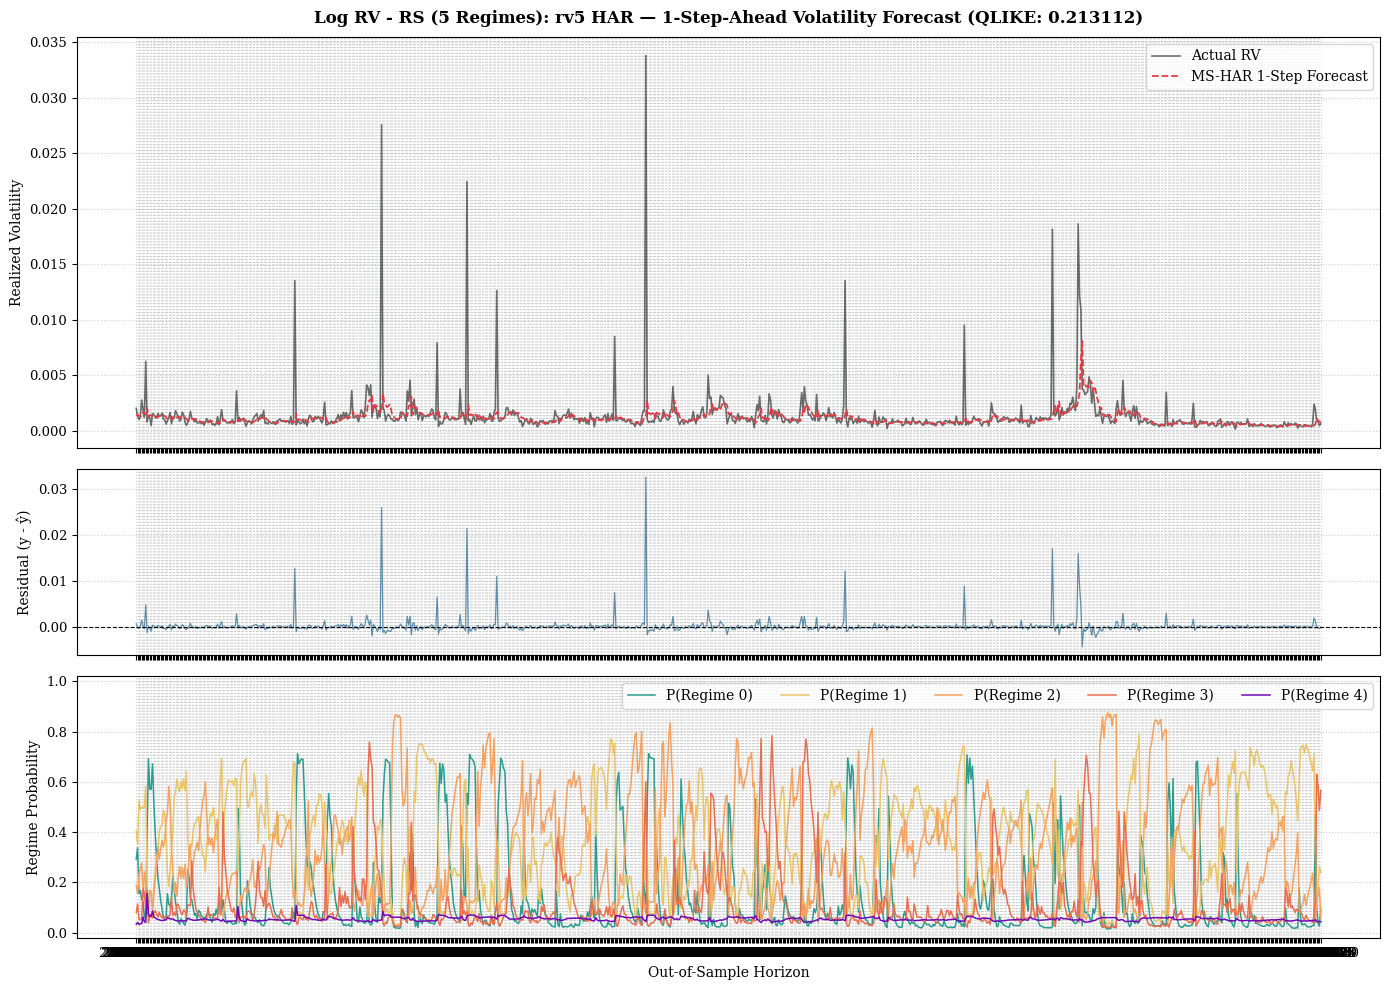

In [9]:
# 1. Run the optimal model specification
best_model_res = run_ms_har_forecasting(
    data=np.log(data),
    target_col='rv5_p',
    exog_cols=['rv5', 'rv5_w', 'rv5_m'],
    train_split=0.80,
    n_regimes=5,
    is_log=True,
    verbose=True
)

# 2. Inspect diagnostics and generate plots
plot_model_diagnostics(
    res=best_model_res,
    data=data,
    train_split=0.80,
    is_log=True,
    model_name="Log RV - RS (5 Regimes): rv5 HAR"
)